In [7]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style = "whitegrid")

In [ ]:
df = pd.read_csv("Wholesale customers data.csv")

In [9]:
X = df.drop(columns=['Channel', 'Region'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [10]:
features = X.columns
X_scaled_df = pd.DataFrame(X_scaled, columns=features, index=X.index)

print("First five scaled records:")
display(X_scaled_df.head())

First five scaled records:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


In [11]:
print("Scaled feature means (approximately zero)")
print(X_scaled_df.mean().round(3))

Scaled feature means (approximately zero)
Fresh              -0.0
Milk                0.0
Grocery            -0.0
Frozen              0.0
Detergents_Paper    0.0
Delicassen         -0.0
dtype: float64


In [13]:
print("Scaled feature standard deviations (approximately one)")
print(X_scaled_df.std(ddof=0).round(3))

Scaled feature standard deviations (approximately one)
Fresh               1.0
Milk                1.0
Grocery             1.0
Frozen              1.0
Detergents_Paper    1.0
Delicassen          1.0
dtype: float64


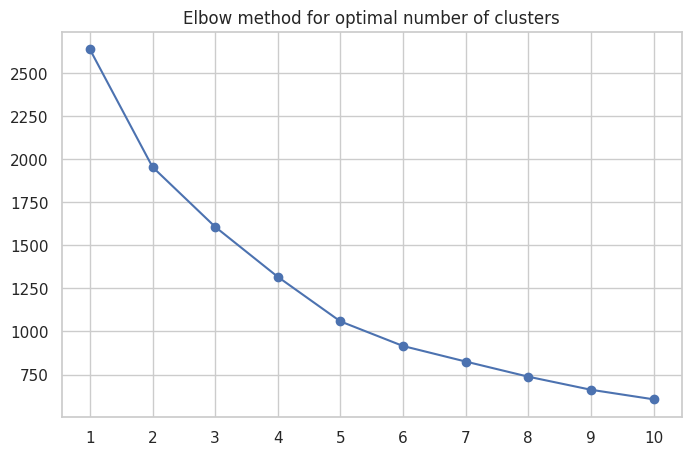

In [17]:
wcss = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), wcss, marker="o")
plt.title("Elbow method for optimal number of clusters")
plt.xticks(list(k_values))
plt.show()

In [18]:
silhouette_values=[]

for k in range(2,11):
    model=KMeans(n_clusters=k,random_state=42,n_init=10)
    labels=model.fit_predict(X_scaled)
    score=silhouette_score(X_scaled,labels)
    silhouette_values.append(score)

silhouette_table=pd.DataFrame({
    "Nummber of Clusters (K)":range(2,11),
    "Silhouette Score":silhouette_values
})
display(silhouette_table.round(4))

,Nummber of Clusters (K),Silhouette Score
0,2,0.5472
1,3,0.5483
2,4,0.3485
3,5,0.3690
4,6,0.3782
5,7,0.3343
6,8,0.3201
7,9,0.3090
8,10,0.3112


In [19]:
suggested_k = int(
    silhouette_table.loc[silhouette_table['Silhouette Score'].idxmax(), 'Nummber of Clusters (K)']
)

print("K suggested_k:", suggested_k)

K suggested_k: 3


In [24]:
K = suggested_k
kmeans_model = KMeans(n_clusters=K, random_state=42, n_init=10)
koc = kmeans_labels = kmeans_model.fit_predict(X_scaled)

In [25]:
df_kmeans=df.copy()
df_kmeans["Kmeans_Clusters"] = kmeans_labels
print("Kmeans clustering completed")
print("Number of cutomers in each cluster: ")
print(df_kmeans["Kmeans_Clusters"].value_counts().sort_index())
display(df_kmeans.head())

Kmeans clustering completed
Number of cutomers in each cluster: 
Kmeans_Clusters
0     45
1    393
2      2
Name: count, dtype: int64


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Kmeans_Clusters
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


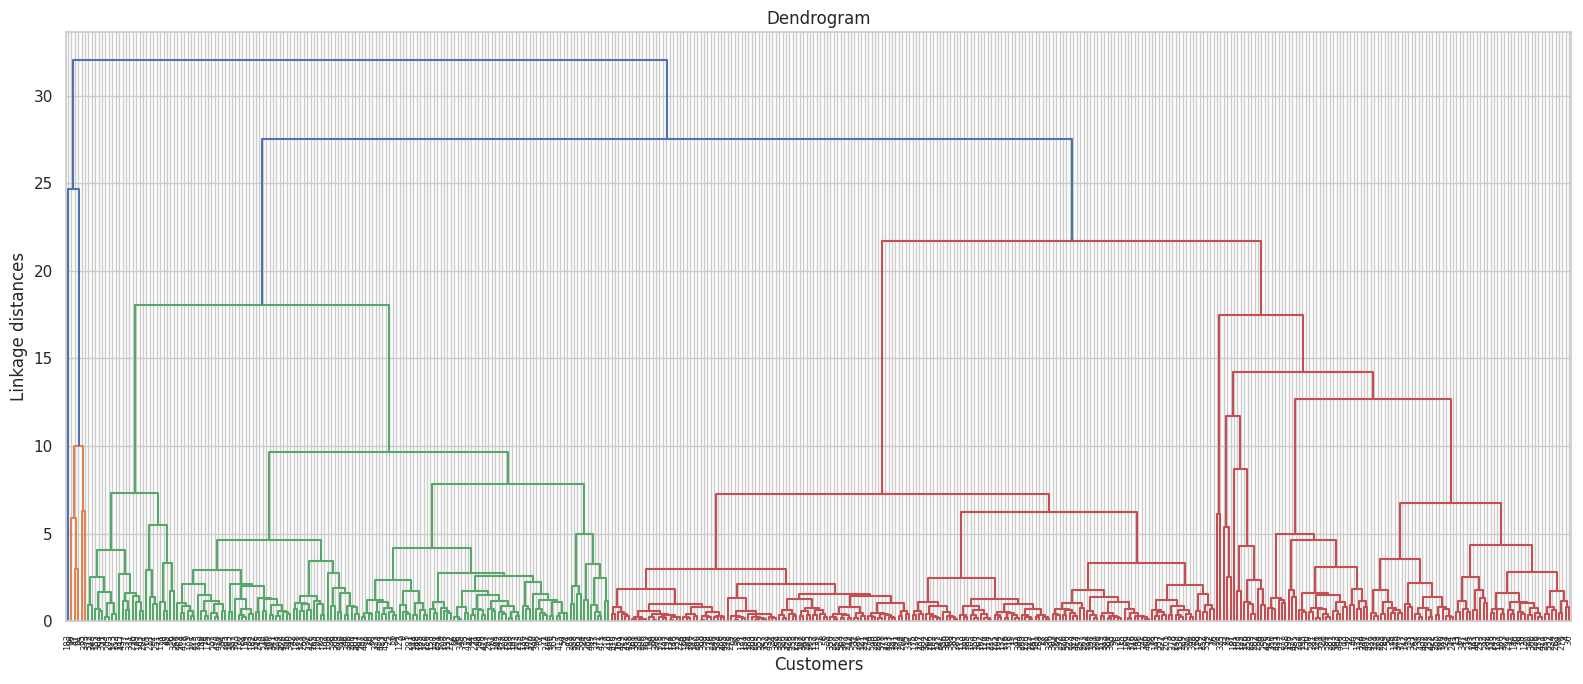

In [27]:
Z = linkage(X_scaled, method="ward", metric="euclidean")

plt.figure(figsize=(16, 7))
dendrogram(Z, leaf_rotation=90, leaf_font_size=6)

plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Linkage distances")
plt.tight_layout()
plt.show()

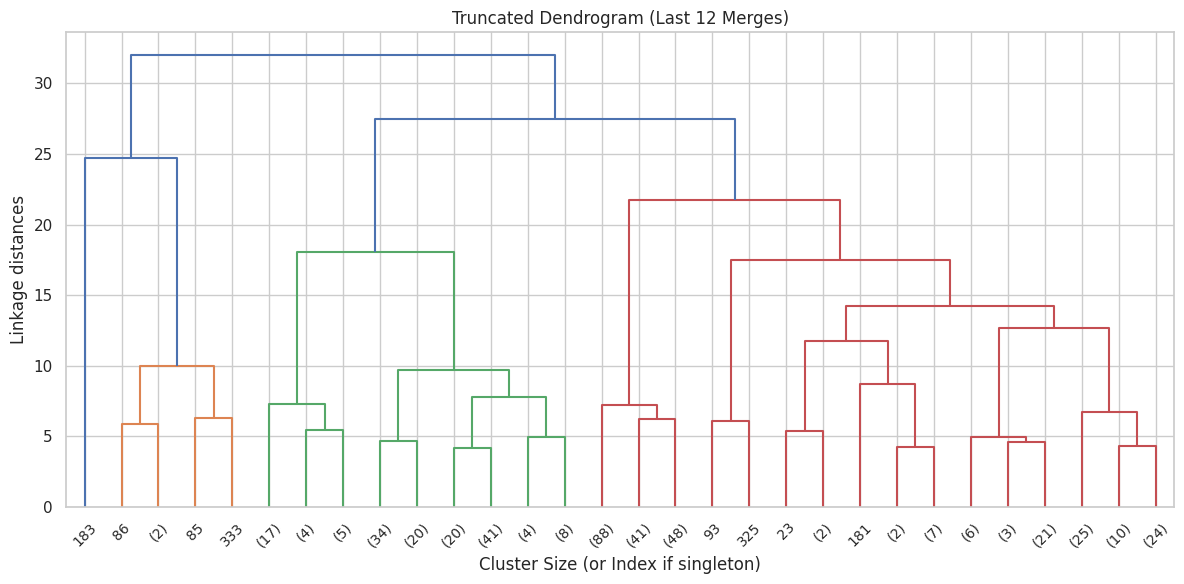

In [28]:
plt.figure(figsize=(12, 6))
dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=45,
    show_leaf_counts=True
)

plt.title("Truncated Dendrogram (Last 12 Merges)")
plt.xlabel("Cluster Size (or Index if singleton)")
plt.ylabel("Linkage distances")
plt.tight_layout()
plt.show()

Variance explained by the two PCA components: 72.46 %


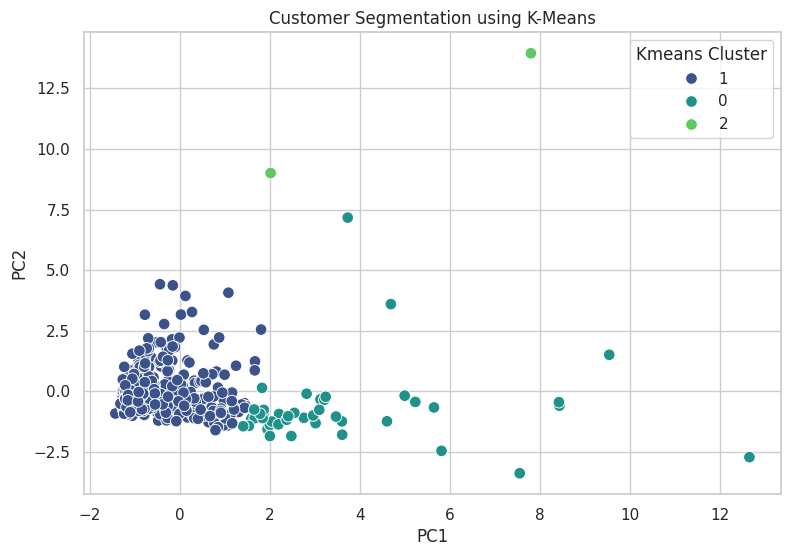

In [34]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Variance explained by the two PCA components:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

plot_df = pd.DataFrame({ "PC1": X_pca[:, 0], "PC2": X_pca[:, 1], "Kmeans Cluster": kmeans_labels.astype(str), "Hierarchical_Cluster": hierarchical_labels.astype(str) })


plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Kmeans Cluster",
    palette="viridis",
    s=70
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [35]:
def evaluate_clustering(X_data, labels, model_name):
  return {
      "Algorithm": model_name,
      "Number of clusters": len(np.unique(labels)),
      "Silhouette score": silhouette_score(X_data, labels)
  }

In [38]:
comparison = pd.DataFrame([
    evaluate_clustering(X_scaled, kmeans_labels, "K-Means"),
    evaluate_clustering(X_scaled, hierarchical_labels, "Hierarchical Clustering")
])
print("Comparison of clustering algorithms")
display(comparison.round(4))

Comparison of clustering algorithms


,Algorithm,Number of clusters,Silhouette score
0,K-Means,3,0.5483
1,Hierarchical Clustering,3,0.2646


In [40]:
cluster_sizes = pd.DataFrame({
    "K-Means": pd.Series(kmeans_labels).value_counts().sort_index(),
    "Hierarchical": pd.Series(hierarchical_labels).value_counts().sort_index()
})

print("Cluster sizes")
display(cluster_sizes)

Cluster sizes


,K-Means,Hierarchical
0,45,6
1,393,281
2,2,153


In [41]:
kmeans_profile = df[features].copy()
kmeans_profile["Cluster"] = kmeans_labels

kmeans_means = kmeans_profile.groupby("Cluster")[features].mean().round(2)

print("Average spending profile of K-means clusters:")
display(kmeans_means)

Average spending profile of K-means clusters:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,10440.93,19386.42,28656.09,2190.24,13327.80,2374.20
1,12062.91,4115.10,5534.97,2940.68,1696.17,1299.11
2,34782.00,30367.00,16898.00,48701.50,755.50,26776.00
